In [1]:
# Import the libraries
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import importlib
import utils
importlib.reload(utils)
from utils import (brand_variant_rules, extract_variant, normalize_variant, get_state_name, get_no_of_owners, 
get_final_dataset)

### Dataset-3

In [2]:
# Import the third dataset from kaggle
path = kagglehub.dataset_download(handle="vanshhala/used-car-dataset", 
                                  output_dir=r".\Raw Datasets\Indian Used Cars Dataset")
df3 = pd.read_csv(os.path.join(path, "Used_Car_Dataset.csv"))
df3.head()

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,Exterior_Body_Color,Interior_Body_Color,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,second,"98,000 km",Silver,Beige,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000","₹ 9,800"
1,Toyota,Innova,2009,15.0,2494,7,Manual,Diesel,second,190000.0 km,Black,Beige,Yes,TS 10,Inactive,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000","₹ 18,800"
2,Volkswagen,VentoTest,2010,14.0,1198,5,Manual,Diesel,first,"77,246 km",Black,Grey,Yes,WB 22,Inactive,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999","₹ 9,200"
3,Maruti Suzuki,Swift,2017,7.0,1197,5,Manual,Diesel,second,"83,500 km",Black,Black,Yes,BR 29,Active,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000","₹ 25,300"
4,Maruti Suzuki,Baleno,2019,5.0,1197,5,Automatic,Petrol,first,"45,000 km",Black,Black,Yes,RJ 50,Inactive,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000","₹ 10,300"


In [3]:
# Derive the value of asking price and convert into numeric value
df3['AskPrice'] = df3['AskPrice'].apply(lambda x: x.split(' ')[1])
df3['AskPrice'] = df3['AskPrice'].str.replace(',', '').astype(int)

In [4]:
# Derive the value of overall cost and convert into numeric value
df3['Overall_Cost'] = df3['Overall_Cost'].apply(lambda x: x.split(' ')[1])
df3['Overall_Cost'] = df3['Overall_Cost'].str.replace(',', '').astype(int)

In [5]:
# Derive the total price by adding asking price and overall cost
df3['TotalPrice'] = df3['Overall_Cost']+df3['AskPrice']
df3.head(1)

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,Exterior_Body_Color,Interior_Body_Color,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,second,"98,000 km",Silver,Beige,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...",195000,9800,204800


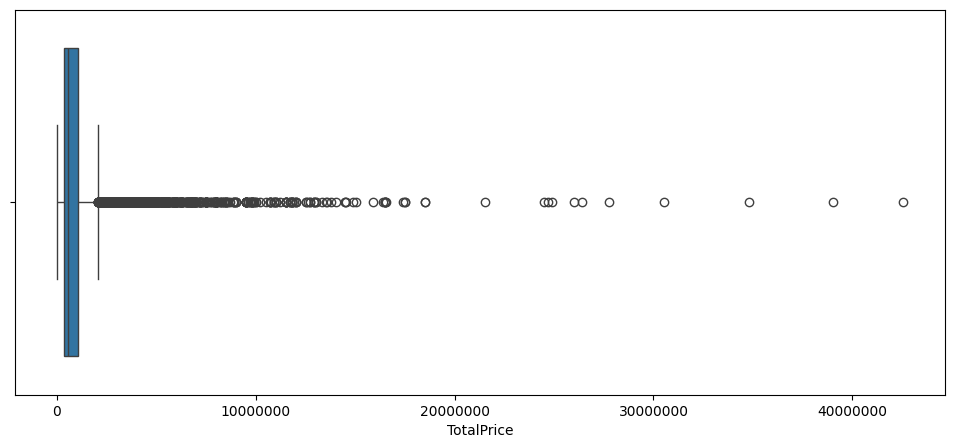

In [6]:
# Visualize the target feature (price)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df3, x='TotalPrice')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

The final price seems to be highly affected by the outliers. The high values needs to be analyzed.

In [7]:
# Investigate the outliers in target feature
df3[df3['TotalPrice']>=5000000]

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,Exterior_Body_Color,Interior_Body_Color,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice
7,BMW,5 Series,2019,5.0,2979,5,Automatic,Diesel,second,"25,000 km",White,Black,Yes,PB 11,Active,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000,25000,5975000
14,Mercedes-Benz,GLE COUPE,2021,3.0,2998,5,Automatic,Petrol,second,"32,000 km",Black,Black,Yes,UP 61,Active,Oct-24,Mercedes-Benz GLE COUPE 3.0 53 AMG 4MATIC Plus...,11800000,9000,11809000
80,Mercedes-Benz,GLC Coupe,2022,2.0,2494,5,Automatic,Diesel,first,"20,000 km",White,Black,Yes,UP 85,Active,Nov-24,Mercedes-Benz GLC Coupe 300d 4MATIC [2020-2023...,7500000,10300,7510300
230,Mercedes-Benz,GLE COUPE,2021,3.0,2979,5,Automatic,Petrol,second,"32,000 km",White,Black,Yes,DL 04,Inactive,Oct-24,Mercedes-Benz GLE COUPE 3.0 53 AMG 4MATIC Plus...,11800000,15400,11815400
279,Mercedes-Benz,G,2011,13.0,2199,5,Automatic,Diesel,second,45000.0 km,Black,Black,Yes,KA 55,Active,Nov-24,"Mercedes-Benz G, 2011, Diesel",7500000,8400,7508400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14583,Volvo,XC60,2023,1.0,1968,5,Automatic,NaN,first,"22,000 km",White,Beige,Yes,GA 01,Active,Nov-24,"Volvo XC60 2.0 B5 Ultimate, 2023, Petrol",6975000,5900,6980900
14682,Mercedes-Benz,GLS,2018,6.0,2996,5,Automatic,Diesel,second,"38,000 km",Black,Black,Yes,WB 11,Inactive,Nov-24,"Mercedes-Benz GLS 350d Grand Edition, 2018, Di...",5600000,5900,5605900
14945,BMW,X6,2016,8.0,2993,5,Automatic,Diesel,second,NaN,Black,Black,Yes,RJ 58,Active,Nov-24,"BMW X6 3.0 XDRIVE 40D M Sport, 2016, Diesel",6000000,25200,6025200
14952,Audi,Q3 Sportback,2013,11.0,1968,5,Automatic,hybrid,second,0 km,White,Black,Yes,KA 37,Active,Dec-24,6.5 marla Commercial building at rama mandi ne...,9500000,8500,9508500


The high price of the cars are justified as these cars belongs to the luxury segment and also some of them are not very old like manufactured after 2020. So, these records can be kept.

In [8]:
df3[df3['TotalPrice']>=5000000]['Brand'].unique()

<ArrowStringArray>
[          'BMW', 'Mercedes-Benz',    'Land Rover',  'Aston Martin',
       'Porsche',         'Lexus',        'Toyota',          'Tata',
          'Audi',        'Jaguar',   'Rolls-Royce',          'Mini',
          'Ford',         'Volvo',          'Jeep', 'Maruti Suzuki',
       'Bentley',      'Maserati',   'Toyota Land',   'Lamborghini',
        'Hummer']
Length: 21, dtype: str

In [9]:
# Find the non luxary cars having price more than 50 lacs
luxury_brands = [ 'BMW', 'Mercedes-Benz', 'Land Rover', 'Aston Martin', 'Porsche', 'Lexus', 'Audi', 
                  'Jaguar', 'Rolls-Royce', 'Mini', 'Volvo', 'Bentley', 'Maserati', 'Lamborghini', 'Hummer']
luxury_models = ['VELLFIRE', 'Land Cruiser', 'Mustang', 'Wrangler', '2.8 Legender 4X2']
df3[(df3['TotalPrice']>=5000000) 
    & ~((df3['Brand'].isin(luxury_brands)|(df3['model'].isin(luxury_models))))][
    ['Brand', 'model', 'Year', 'TotalPrice']]

,Brand,model,Year,TotalPrice
1231,Tata,Punch,2022,6505600
6611,Toyota,Innova,2013,9523100
7167,Maruti Suzuki,Baleno,2016,5010400
7803,Tata,Curvv,2019,7221600
11006,Toyota Land,Cruiser,2013,8229300
11534,Toyota Land,Cruiser,2017,16514000
14345,Toyota Land,Cruiser,2008,6012800


In [10]:
# Remove the erronous data from the dataset
df3.drop(index=[1231, 6611, 7167, 7803], axis=0, inplace=True)

In [11]:
# Check for unique brands
print(sorted(df3['Brand'].unique()))

['Ambassador', 'Ashok', 'Aston Martin', 'Audi', 'BMW', 'Bajaj', 'Bentley', 'Chevrolet', 'Citroen', 'Datsun', 'Fiat', 'Force', 'Ford', 'Honda', 'Hummer', 'Hyundai', 'ICML', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Lamborghini', 'Land Rover', 'Lexus', 'MG', 'Mahindra', 'Maruti Suzuki', 'Maserati', 'Mercedes-Benz', 'Mini', 'Mitsubishi', 'Nissan', 'Opel', 'Porsche', 'Renault', 'Rolls-Royce', 'Skoda', 'Ssangyong', 'Tata', 'Toyota', 'Toyota Land', 'Volkswagen', 'Volvo']


In [12]:
# Rename Kia with KIA
df3['Brand'] = df3['Brand'].replace('Kia', 'KIA')

In [13]:
# Apply the varient extraction function to the dataframe
df3['variant'] = df3.apply(lambda row: extract_variant(row['AdditionInfo'], row['Brand']), axis=1)
df3.head()

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,...,Interior_Body_Color,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice,variant
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,second,"98,000 km",...,Beige,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...",195000,9800,204800,V
1,Toyota,Innova,2009,15.0,2494,7,Manual,Diesel,second,190000.0 km,...,Beige,Yes,TS 10,Inactive,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000,18800,393800,G
2,Volkswagen,VentoTest,2010,14.0,1198,5,Manual,Diesel,first,"77,246 km",...,Grey,Yes,WB 22,Inactive,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999,9200,194199,NaN
3,Maruti Suzuki,Swift,2017,7.0,1197,5,Manual,Diesel,second,"83,500 km",...,Black,Yes,BR 29,Active,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000,25300,590300,NaN
4,Maruti Suzuki,Baleno,2019,5.0,1197,5,Automatic,Petrol,first,"45,000 km",...,Black,Yes,RJ 50,Inactive,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000,10300,695300,ALPHA


In [14]:
# Fetch the fuel type of the model from additional info
missing_fueltype_index = df3['FuelType'].isna()
df3.loc[missing_fueltype_index, 'FuelType'] = df3.loc[missing_fueltype_index, 'AdditionInfo'].str.extract(
    r'\b(Petrol|Diesel|CNG|Electric)\b', flags=re.IGNORECASE, expand=False)

In [15]:
# Check for the data where variant is missing
len(df3[df3['variant'].isna()])

5005

Around 5000 out of 15000 records, the varient could not be found. So, it will be kept as Null or later fetched from other sources.

In [16]:
# Fetch the state name from vehicle registration number
df3['state'] = get_state_name(df3['Registration_Number'])
df3.head()

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,...,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice,variant,state
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,second,"98,000 km",...,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...",195000,9800,204800,V,Uttar Pradesh
1,Toyota,Innova,2009,15.0,2494,7,Manual,Diesel,second,190000.0 km,...,Yes,TS 10,Inactive,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000,18800,393800,G,Telangana
2,Volkswagen,VentoTest,2010,14.0,1198,5,Manual,Diesel,first,"77,246 km",...,Yes,WB 22,Inactive,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999,9200,194199,NaN,West Bengal
3,Maruti Suzuki,Swift,2017,7.0,1197,5,Manual,Diesel,second,"83,500 km",...,Yes,BR 29,Active,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000,25300,590300,NaN,Bihar
4,Maruti Suzuki,Baleno,2019,5.0,1197,5,Automatic,Petrol,first,"45,000 km",...,Yes,RJ 50,Inactive,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000,10300,695300,ALPHA,Rajasthan


In [17]:
# Extract the number from kmDriven column
df3['kmDriven'] = df3['kmDriven'].str.split().str[0].str.replace(',', '')
df3['kmDriven'] = df3['kmDriven'].astype(float)
df3.head(1)

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,...,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice,variant,state
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,second,98000.0,...,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...",195000,9800,204800,V,Uttar Pradesh


In [18]:
df3['Owner'] = get_no_of_owners(df3['Owner'])
df3.head(1)

,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,...,Has_Insurance,Registration_Number,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost,TotalPrice,variant,state
0,Honda,City,2001,23.0,1497,5,Manual,Petrol,2,98000.0,...,Yes,UP 82,Active,Nov-24,"Honda City v teck in mint condition, valid gen...",195000,9800,204800,V,Uttar Pradesh


In [19]:
# Apply the normalization function to the model and variant
df3['model'] = df3['model'].apply(normalize_variant)
df3['variant'] = df3['variant'].apply(normalize_variant)

In [20]:
# Change the datatype of model and variant to string
df3['model'] = df3['model'].astype(str)
df3['variant'] = df3['variant'].astype(str)

In [21]:
# Check for unique model and variant after normalization
print('Unique Model\n', df3['model'].unique())
print('Unique Variant\n', df3['variant'].unique())

Unique Model
 <ArrowStringArray>
[               'CITY',              'INNOVA',           'VENTOTEST',
               'SWIFT',              'BALENO',                  'X3',
            '5 SERIES', 'MARUTI-SUZUKI-DZIRE',            'ECOSPORT',
            'ALTO-K10',
 ...
                  'H2',             'R-CLASS',             'IMPERIO',
    'SONATA TRANSFORM',                  'A8',               'VERSA',
               'T-ROC',             'X-TRAIL',             'VENTURY',
                'YETI']
Length: 428, dtype: str
Unique Variant
 <ArrowStringArray>
[       'V',        'G',        nan,    'ALPHA',       'VX',     '530D',
      'VXI', 'TITANIUM',  'PREMIUM',        'S',
 ...
     'C 63',  '55 TFSI',   'AMG 63',    'C 250',       'H2', 'GLS 450D',
       'PS',     'C200',   'SPORT+',   'ZDI(O)']
Length: 364, dtype: str


### Preparing the Final Dataset

In [4]:
# Create the mapping for dataframe-3
column_mapping = {'Brand': 'brand', 'Year': 'make_year', 'kmDriven': 'km_driven', 'Transmission': 'transmission', 
                  'Owner': 'previous_owners', 'FuelType': 'fuel_type', 'Engine_Capacity_CC': 'engine_capacity_cc', 
                  'Seating_Capacity': 'seats', 'Exterior_Body_Color': 'exterior_color', 'TotalPrice': 'price'}

In [5]:
# Rename the columns
df3 = df3.rename(columns=column_mapping)

In [24]:
# Keep only required columns and create missing ones as NaN
df3 = get_final_dataset(df3)
df3.head()

,brand,model,variant,body_type,make_year,state,km_driven,transmission,previous_owners,fuel_type,...,front_brake_type,rear_brake_type,boot_space,fuel_supply_system,alloy_wheel_size,max_power_delivered,max_power_at,max_torque_delivered,max_torque_at,price
0,Honda,CITY,V,NaN,2001,Uttar Pradesh,98000.0,Manual,2,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,204800
1,Toyota,INNOVA,G,NaN,2009,Telangana,190000.0,Manual,2,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,393800
2,Volkswagen,VENTOTEST,NaN,NaN,2010,West Bengal,77246.0,Manual,1,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,194199
3,Maruti Suzuki,SWIFT,NaN,NaN,2017,Bihar,83500.0,Manual,2,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,590300
4,Maruti Suzuki,BALENO,ALPHA,NaN,2019,Rajasthan,45000.0,Automatic,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,695300


In [25]:
# Save the standardized dataset into local machine
df3.to_csv(r'.\Cleaned Datasets\dataset_3.csv', index=False)